In [1]:
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("SmartMove setup completed!")

TensorFlow version: 2.21.0
NumPy version: 2.1.3
SmartMove setup completed!


In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00240/"
    "UCI%20HAR%20Dataset.zip"
)

zip_path = "/content/UCI_HAR_Dataset.zip"
data_dir = "/content/UCI HAR Dataset"

if not os.path.exists(data_dir):
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content")

print("Dataset ready:", os.path.exists(data_dir))

Dataset ready: True


In [3]:
base = "/content/UCI HAR Dataset"

signal_names = [
    "body_acc_x_", "body_acc_y_", "body_acc_z_",
    "body_gyro_x_", "body_gyro_y_", "body_gyro_z_",
    "total_acc_x_", "total_acc_y_", "total_acc_z_"
]

def load_signals(split):
    folder = os.path.join(base, split, "Inertial Signals")

    channels = []
    for name in signal_names:
        path = os.path.join(folder, name + split + ".txt")
        channels.append(np.loadtxt(path))

    return np.stack(channels, axis=-1)

X_train = load_signals("train")
X_test = load_signals("test")

y_train = np.loadtxt(
    os.path.join(base, "train", "y_train.txt"),
    dtype=int
) - 1

y_test = np.loadtxt(
    os.path.join(base, "test", "y_test.txt"),
    dtype=int
) - 1

activity_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (7352, 128, 9)
Testing data: (2947, 128, 9)
Training labels: (7352,)
Testing labels: (2947,)


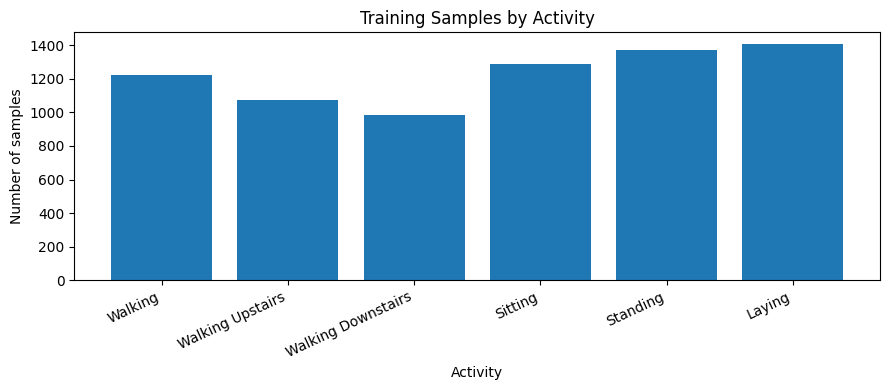

In [4]:
counts = pd.Series(y_train).value_counts().sort_index()

plt.figure(figsize=(9, 4))
plt.bar(activity_names, counts.values)
plt.title("Training Samples by Activity")
plt.xlabel("Activity")
plt.ylabel("Number of samples")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

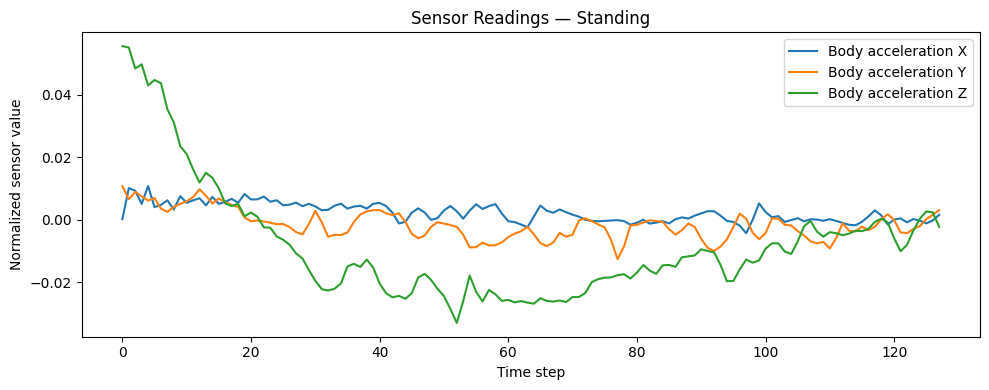

In [5]:
sample = X_train[0]

plt.figure(figsize=(10, 4))
plt.plot(sample[:, 0], label="Body acceleration X")
plt.plot(sample[:, 1], label="Body acceleration Y")
plt.plot(sample[:, 2], label="Body acceleration Z")

plt.title(
    "Sensor Readings — "
    + activity_names[y_train[0]]
)
plt.xlabel("Time step")
plt.ylabel("Normalized sensor value")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout
)

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(128, 9)),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(6, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,222 (82.90 KB)

 Trainable params: 21,222 (82.90 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - accuracy: 0.4569 - loss: 1.3103 - val_accuracy: 0.4751 - val_loss: 1.2016
Epoch 2/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.6236 - loss: 0.9013 - val_accuracy: 0.6383 - val_loss: 0.8584
Epoch 3/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.7185 - loss: 0.6897 - val_accuracy: 0.6718 - val_loss: 0.8879
Epoch 4/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.8149 - loss: 0.4890 - val_accuracy: 0.8477 - val_loss: 0.6802
Epoch 5/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.8878 - loss: 0.3466 - val_accuracy: 0.8205 - val_loss: 0.6760
Epoch 6/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - accuracy: 0.9217 - loss: 0.2501 - val_accuracy: 0.8722 - val_loss: 0.5559
Epoch 7/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.9373 - loss: 0.1901 - val_accuracy: 0.8722 - val_loss: 0.5667
Epoch 8/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.9469 - loss: 0.1639 - val_accuracy: 0.8740 

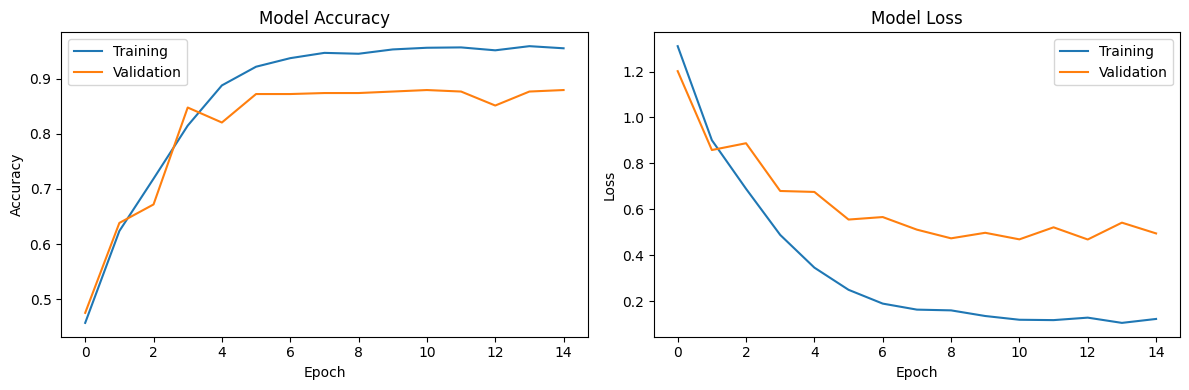

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(6)),
    target_names=activity_names,
    zero_division=0
))

Test accuracy: 89.82%
Test loss: 0.3184

Classification Report:
                    precision    recall  f1-score   support

           Walking       0.96      0.95      0.96       496
  Walking Upstairs       0.90      0.92      0.91       471
Walking Downstairs       0.92      0.98      0.95       420
           Sitting       0.77      0.85      0.81       491
          Standing       0.86      0.75      0.80       532
            Laying       1.00      0.95      0.97       537

          accuracy                           0.90      2947
         macro avg       0.90      0.90      0.90      2947
      weighted avg       0.90      0.90      0.90      2947



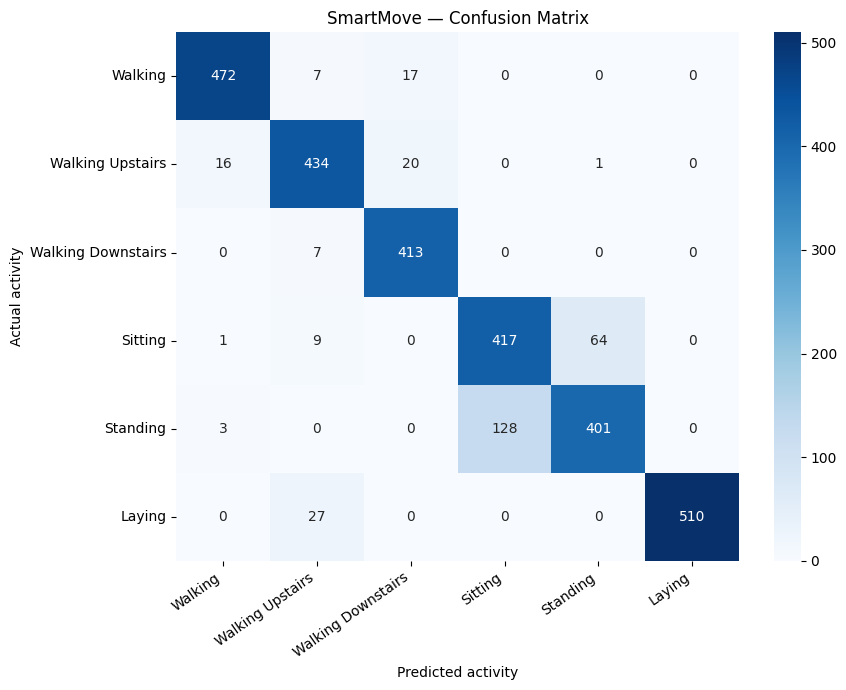

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(6))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_names,
    yticklabels=activity_names
)

plt.xlabel("Predicted activity")
plt.ylabel("Actual activity")
plt.title("SmartMove — Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Predicted activity: Standing
Estimated confidence: 98.47%


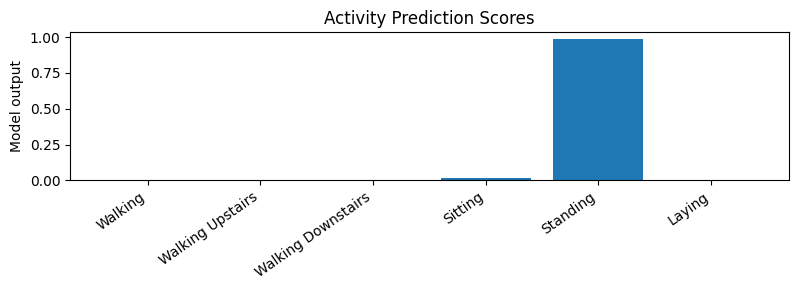

In [11]:
def predict_activity(sample_index):
    sample = X_test[sample_index:sample_index + 1]

    probs = model.predict(sample, verbose=0)[0]
    predicted_class = int(np.argmax(probs))

    print("Predicted activity:", activity_names[predicted_class])
    print(f"Estimated confidence: {probs[predicted_class] * 100:.2f}%")

    plt.figure(figsize=(8, 3))
    plt.bar(activity_names, probs)
    plt.ylabel("Model output")
    plt.title("Activity Prediction Scores")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

predict_activity(0)

In [12]:
model.save("/content/smartmove_lstm.keras")

print("SmartMove model saved successfully!")

SmartMove model saved successfully!


In [13]:
from google.colab import files

files.download("/content/smartmove_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>